# 07. Transisi dan kestabilan profil historis

Lacak profil setiap grid selama 2021Q1-2025Q4 menggunakan label satu model historis. Ukuran transisi adalah deskriptif; bukan bukti perubahan tektonik kausal.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../06_model_evaluation/06_model_evaluation.ipynb) | [Berikutnya](../08_stability/08_stability.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Definisi pasangan, pergantian, dan durasi](#s2)
- [3. Ekspor riwayat, matriks dan durasi](#s3)
- [4. Jalankan analisis temporal](#s4)
- [5. Riwayat grid yang dapat dipilih](#s5)

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_model, load_prepared, write_json
from src.modeling import cluster_metrics
from src.preprocessing import grid_panel

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning\seismic_research_2021_2025
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Definisi pasangan, pergantian, dan durasi

Hanya dua triwulan berurutan yang sama-sama mempunyai profil cluster dihitung sebagai pasangan comparable. Noise, NO_EVENTS, dan fitur tidak lengkap memutus run. Stability rate = 1 - jumlah pergantian / pasangan comparable. Jika tidak ada pasangan, hasil NaN. State transition disimpan terpisah agar nol/noise tetap dapat diperiksa.

In [2]:
def temporal_tables(labels):
    data = labels.sort_values(["grid_id", "period"]).copy()
    data["previous_profile"] = data.groupby("grid_id")["profile"].shift()
    data["previous_period"] = data.groupby("grid_id")["period"].shift()
    data["is_profile"] = data["profile"].str.contains("_P", regex=False)
    previous_is_profile = data["previous_profile"].fillna("").str.contains("_P", regex=False)
    ordinal = pd.PeriodIndex(data["period"], freq="Q").asi8
    previous_ordinal = pd.Series(ordinal, index=data.index).groupby(data["grid_id"]).shift()
    adjacent = ordinal - previous_ordinal == 1
    data["comparable"] = data["is_profile"] & previous_is_profile & adjacent
    data["changed"] = data["comparable"] & data["profile"].ne(data["previous_profile"])
    transitions = pd.crosstab(data.loc[data["comparable"], "previous_profile"], data.loc[data["comparable"], "profile"])
    state_transitions = pd.crosstab(data.loc[adjacent, "previous_profile"], data.loc[adjacent, "profile"])
    summaries, spells = [], []
    for grid_id, group in data.groupby("grid_id", sort=True):
        group = group.copy()
        group["run"] = (group["profile"].ne(group["profile"].shift()) | ~adjacent.loc[group.index]).cumsum()
        valid_spells = []
        for _, run in group.groupby("run"):
            if run["is_profile"].all():
                duration = len(run)
                valid_spells.append(duration)
                spells.append({"grid_id": grid_id, "profile": run.iloc[0]["profile"], "start": run.iloc[0]["period"],
                               "end": run.iloc[-1]["period"], "duration_quarters": duration})
        n = int(group["comparable"].sum())
        changes = int(group["changed"].sum())
        summaries.append({"grid_id": grid_id, "n_profile_quarters": int(group["is_profile"].sum()),
                          "n_comparable_pairs": n, "n_profile_changes": changes,
                          "stability_rate": 1-changes/n if n else np.nan,
                          "max_profile_run_quarters": max(valid_spells, default=0),
                          "n_no_event_quarters": int(group["profile"].eq("NO_EVENTS").sum()),
                          "n_noise_quarters": int(group["profile"].eq("NOISE").sum())})
    return data, pd.DataFrame(summaries), transitions, state_transitions, pd.DataFrame(spells)

<a id="s3"></a>
## 3. Ekspor riwayat, matriks dan durasi

Simpan history, grid_stability, profile_transitions, state_transitions, transition_probabilities dan profile_spells untuk masing-masing metode.

In [3]:
def temporal(root=ROOT):
    root = Path(root)
    load_prepared(root)
    outputs = {}
    for method in ["kmeans", "dbscan"]:
        load_model(root, method)
        labels = pd.read_csv(root / f"models/{method}/training_labels.csv")
        tables = temporal_tables(labels)
        output = root / f"reports/temporal/{method}"
        output.mkdir(exist_ok=True)
        for name, table in zip(["history", "grid_stability", "profile_transitions", "state_transitions", "profile_spells"], tables):
            table.to_csv(output / f"{name}.csv", index=name in ["profile_transitions", "state_transitions"])
        matrix = tables[2]
        matrix.div(matrix.sum(axis=1).replace(0, np.nan), axis=0).to_csv(output / "transition_probabilities.csv")
        if not matrix.empty:
            fig, ax = plt.subplots(figsize=(7,6))
            im = ax.imshow(matrix.to_numpy(), cmap="Blues")
            ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=60, ha="right")
            ax.set_yticks(range(len(matrix.index)), matrix.index)
            ax.set(xlabel="Profil berikutnya", ylabel="Profil sebelumnya", title=f"{method.upper()}: transisi berurutan 2021-2025")
            fig.colorbar(im, ax=ax, label="Jumlah pasangan grid-triwulan")
            fig.tight_layout()
            fig.savefig(root / f"reports/figures/{method}_transitions.png", dpi=160)
            plt.close(fig)
        outputs[method] = tables[1]
    return outputs

<a id="s4"></a>
## 4. Jalankan analisis temporal



### KMEANS

,grid_id,n_profile_quarters,n_comparable_pairs,n_profile_changes,stability_rate,max_profile_run_quarters,n_no_event_quarters,n_noise_quarters
1444,3_-13,20,19,17,0.105263,2,0,0
932,17_17,20,19,17,0.105263,2,0,0
930,17_15,20,19,16,0.157895,3,0,0
1550,48_-3,20,19,16,0.157895,4,0,0
770,12_4,20,19,16,0.157895,2,0,0
1016,1_-17,19,17,15,0.117647,2,1,0
1526,46_-1,20,19,15,0.210526,3,0,0
1537,47_-1,19,17,15,0.117647,2,1,0
1138,23_-3,19,18,15,0.166667,3,1,0
993,19_12,20,19,15,0.210526,3,0,0


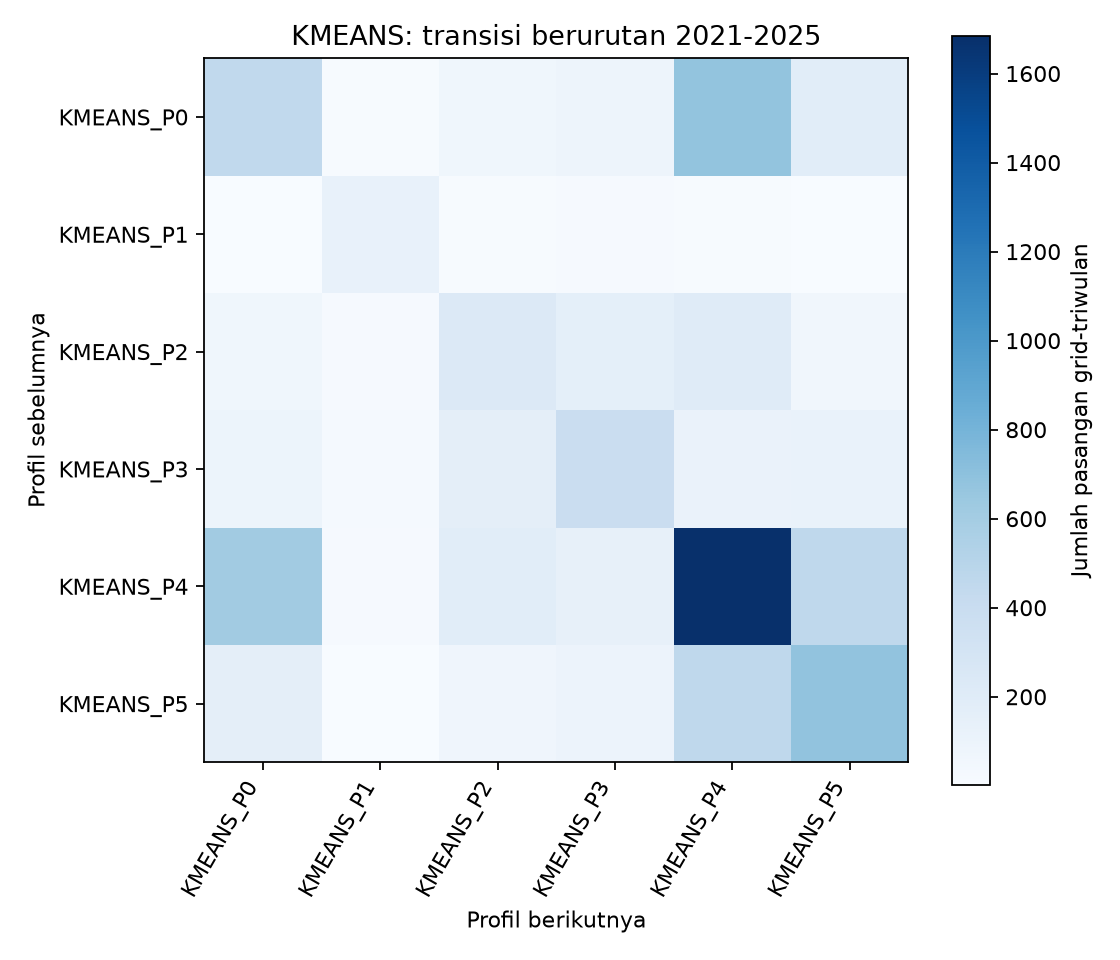

### DBSCAN

,grid_id,n_profile_quarters,n_comparable_pairs,n_profile_changes,stability_rate,max_profile_run_quarters,n_no_event_quarters,n_noise_quarters
927,17_12,19,17,14,0.176471,2,1,0
713,11_-14,15,12,12,0.000000,1,5,0
1071,21_-2,19,18,12,0.333333,3,1,0
124,-1_-14,15,12,12,0.000000,1,4,1
1138,23_-3,18,16,12,0.250000,4,1,1
1105,22_-3,16,13,12,0.076923,2,2,2
1012,1_-13,17,13,12,0.076923,2,1,2
662,0_-15,15,12,12,0.000000,1,4,1
747,12_-14,15,11,11,0.000000,1,5,0
566,-4_-14,16,12,11,0.083333,2,4,0


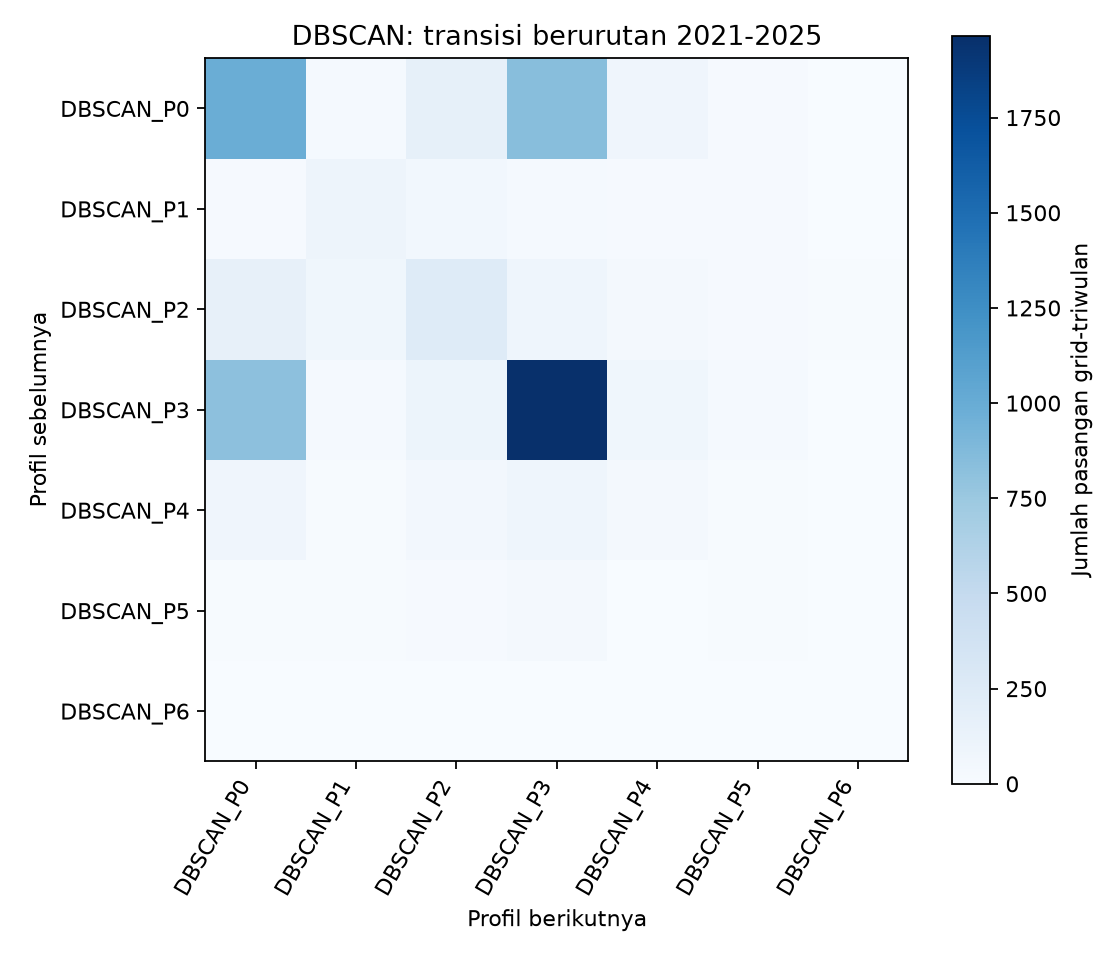

In [4]:
stability_by_grid = temporal(ROOT)
for method, summary in stability_by_grid.items():
    display(Markdown(f"### {method.upper()}"))
    display(summary.sort_values("n_profile_changes",ascending=False).head(15))
    display(Image(filename=str(ROOT / f"reports/figures/{method}_transitions.png")))

<a id="s5"></a>
## 5. Riwayat grid yang dapat dipilih

Nama deskriptif yang dibuat pada notebook 04 dipakai kembali di sini; tidak ada pengelompokan baru. Ganti GRID_ID sesuai tabel dan periksa perubahan nama bersama jumlah kejadian, magnitudo serta kedalaman.

In [5]:
from src.mapping import profile_descriptions
history = pd.read_csv(ROOT / "reports/temporal/kmeans/history.csv")
descriptions = profile_descriptions(ROOT, "kmeans", cfg)
history["nama_kelompok"] = history["profile"].map(lambda code: descriptions[code]["name"])
GRID_ID = history.groupby("grid_id")["earthquake_count"].sum().idxmax()
with pd.option_context("display.max_colwidth", None):
    display(history.loc[history["grid_id"].eq(GRID_ID),["grid_id","period","nama_kelompok","earthquake_count","avg_magnitude","avg_depth","low_support","changed"]].sort_values("period"))

,grid_id,period,nama_kelompok,earthquake_count,avg_magnitude,avg_depth,low_support,changed
14780,11_5,2021Q1,Kelompok F: Kejadian lebih sering; cenderung dangkal,13,3.538462,91.076923,False,False
14781,11_5,2021Q2,Kelompok F: Kejadian lebih sering; cenderung dangkal,13,3.769231,105.000000,False,False
14782,11_5,2021Q3,Kelompok F: Kejadian lebih sering; cenderung dangkal,20,3.790000,141.600000,False,False
14783,11_5,2021Q4,Kelompok F: Kejadian lebih sering; cenderung dangkal,9,3.466667,114.111111,False,False
14784,11_5,2022Q1,Kelompok F: Kejadian lebih sering; cenderung dangkal,8,3.487500,69.000000,False,False
14785,11_5,2022Q2,Kelompok F: Kejadian lebih sering; cenderung dangkal,15,3.646667,91.466667,False,False
14786,11_5,2022Q3,Kelompok F: Kejadian lebih sering; cenderung dangkal,22,3.813636,106.590909,False,False
14787,11_5,2022Q4,Kelompok F: Kejadian lebih sering; cenderung dangkal,12,3.716667,102.666667,False,False
14788,11_5,2023Q1,Kelompok F: Kejadian lebih sering; cenderung dangkal,15,3.700000,115.733333,False,False
14789,11_5,2023Q2,Kelompok F: Kejadian lebih sering; cenderung dangkal,24,3.504167,116.041667,False,False


## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.